In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import os
import glob

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Find the dataset file
files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

print("Available CSV files:")
for file in files:
    print(file)

Available CSV files:
/kaggle/input/datasets/niteshyadav3103/concrete-compressive-strength/Concrete Compressive Strength.csv


In [3]:
# Load the dataset
data_path = files[0]
df = pd.read_csv(data_path)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset Shape: (1030, 9)

First 5 Rows:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age (day),Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Cement                          1030 non-null   float64
 1   Blast Furnace Slag              1030 non-null   float64
 2   Fly Ash                         1030 non-null   float64
 3   Water                           1030 non-null   float64
 4   Superplasticizer                1030 non-null   float64
 5   Coarse Aggregate                1030 non-null   float64
 6   Fine Aggregate                  1030 non-null   float64
 7   Age (day)                       1030 non-null   int64  
 8   Concrete compressive strength   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing Values:
Cement                            0
Blast Furnace Slag                0
Fly Ash                           0
Water                    

In [7]:
# Separate features and target

X = df.drop(columns=['Concrete compressive strength ']).values

y = df['Concrete compressive strength '].values.reshape(-1, 1)


print("Features shape:", X.shape)
print("Target shape:", y.shape)


# Split data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Scale input features

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)


# Scale target variable

scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)


# Generate polynomial features

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)


print("\nPolynomial Regression Results:")
print("Original features:", X_train_scaled.shape[1])
print("Polynomial features:", X_train_poly.shape[1])
print("Training data shape:", X_train_poly.shape)
print("Testing data shape:", X_test_poly.shape)

Features shape: (1030, 8)
Target shape: (1030, 1)

Polynomial Regression Results:
Original features: 8
Polynomial features: 44
Training data shape: (824, 44)
Testing data shape: (206, 44)


In [6]:
print(df.columns.tolist())

['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age (day)', 'Concrete compressive strength ']


In [9]:
# Prediction function

def predict(X, weights, bias):
    return X @ weights + bias


# Loss function

def compute_loss(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)


# Gradient calculation

def compute_gradients(X, y, weights, bias):

    m = X.shape[0]

    predictions = predict(X, weights, bias)

    errors = predictions - y

    dw = (2 / m) * (X.T @ errors)

    db = (2 / m) * np.sum(errors)

    return dw, db


print("Model functions defined successfully!")

Model functions defined successfully!


In [10]:
def train_gd_momentum(X, y, learning_rate=0.01,
                      momentum=0.9, epochs=1000):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    velocity_w = np.zeros_like(weights)
    velocity_b = 0.0

    loss_history = []

    for epoch in range(epochs):

        dw, db = compute_gradients(X, y, weights, bias)

        # Momentum update
        velocity_w = momentum * velocity_w + dw
        velocity_b = momentum * velocity_b + db

        # Update parameters
        weights -= learning_rate * velocity_w
        bias -= learning_rate * velocity_b

        # Calculate loss
        predictions = predict(X, weights, bias)
        loss = compute_loss(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


# Train the model
gd_weights, gd_bias, gd_loss = train_gd_momentum(
    X_train_poly,
    y_train_scaled
)

print("Gradient Descent with Momentum")
print("Final Training Loss:", gd_loss[-1])

Gradient Descent with Momentum
Final Training Loss: 0.18882647375403835


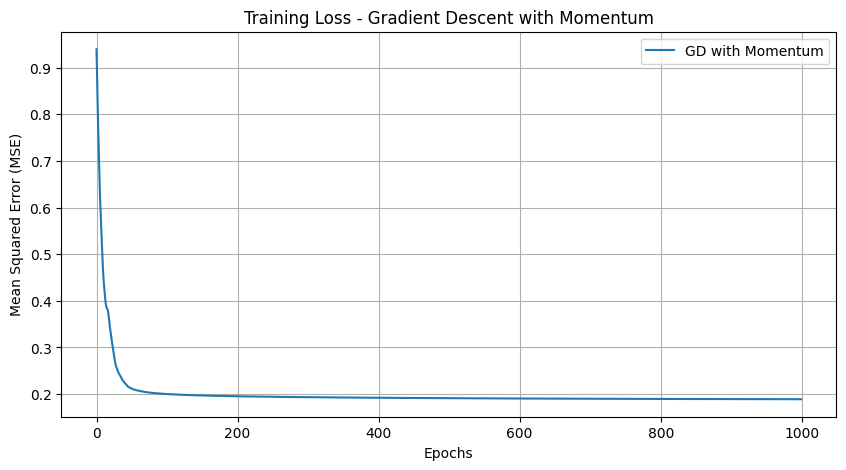

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(gd_loss, label='GD with Momentum')

plt.title('Training Loss - Gradient Descent with Momentum')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')

plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Make predictions
predictions_scaled = predict(
    X_test_poly,
    gd_weights,
    gd_bias
)

# Convert predictions to original scale
predictions = scaler_y.inverse_transform(predictions_scaled)
actual = scaler_y.inverse_transform(y_test_scaled)

# Calculate evaluation metrics
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual, predictions)
r2 = r2_score(actual, predictions)

# Display results
gd_results = pd.DataFrame([{
    "Optimizer": "GD with Momentum",
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "R2 Score": r2
}])

display(gd_results.round(4))


,Optimizer,MSE,RMSE,MAE,R2 Score
0,GD with Momentum,55.1723,7.4278,5.965,0.7859


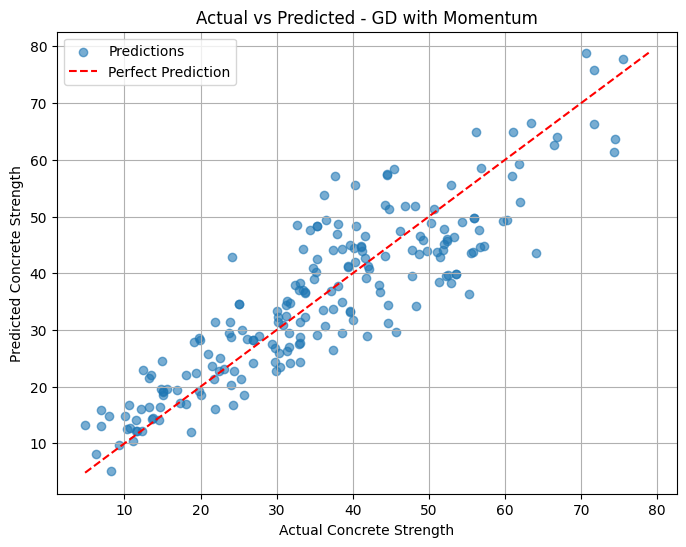

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(actual, predictions, alpha=0.6, label='Predictions')

# Ideal prediction line
min_value = min(actual.min(), predictions.min())
max_value = max(actual.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted - GD with Momentum')
plt.xlabel('Actual Concrete Strength')
plt.ylabel('Predicted Concrete Strength')

plt.legend()
plt.grid(True)
plt.show()


## Conclusion – Gradient Descent with Momentum

In this notebook, Polynomial Regression with Gradient Descent and Momentum was implemented to predict concrete compressive strength.

The model was trained using polynomial features of degree 2, with a learning rate of 0.01, momentum of 0.9, and 1000 training epochs.

The model achieved the following results:

- **MSE:** 55.1723
- **RMSE:** 7.4278
- **MAE:** 5.9650
- **R² Score:** 0.7859

The training loss curve showed that the model converged successfully. The Actual vs Predicted plot also demonstrated a reasonable agreement between actual and predicted values.

Overall, Gradient Descent with Momentum provided good predictive performance for the Concrete Compressive Strength dataset.